In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
grace_path = "/home/mgurazada/snowdroughts_thirst/data/grace_data/original_data/GRCTellus.JPL.200204_202508.GLO.RL06.3M.MSCNv04CRI.nc"
grace_data = xr.open_dataset(grace_path)
grace_data.time.values
# subset GRACE from 2002-04-01 to 2024-12-31
grace_data = grace_data.sel(time=slice("2002-04-01", "2024-12-31"))
# collapse to one value per calendar month (first-of-month stamp), averaging duplicates # dups = ["2012-01-01", "2015-04-01"]
# grace_data = grace_data.resample(time="MS").mean()
grace_data

<xarray.Dataset> Size: 1GB
Dimensions:        (time: 240, lat: 360, lon: 720, bounds: 2)
Coordinates:
  * time           (time) datetime64[ns] 2kB 2002-04-17T12:00:00 ... 2024-12-...
  * lat            (lat) float64 3kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
  * lon            (lon) float64 6kB 0.25 0.75 1.25 1.75 ... 358.8 359.2 359.8
Dimensions without coordinates: bounds
Data variables:
    lwe_thickness  (time, lat, lon) float64 498MB ...
    uncertainty    (time, lat, lon) float64 498MB ...
    lat_bounds     (lat, bounds) float64 6kB ...
    lon_bounds     (lon, bounds) float64 12kB ...
    time_bounds    (time, bounds) datetime64[ns] 4kB ...
    land_mask      (lat, lon) float64 2MB ...
    scale_factor   (lat, lon) float64 2MB ...
    mascon_ID      (lat, lon) float64 2MB ...
    GAD            (time, lat, lon) float64 498MB ...
Attributes: (12/53)
    Conventions:                   CF-1.6, ACDD-1.3, ISO 8601
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    standard_name_vocabulary:      NetCDF Climate and Forecast (CF) Metadata ...
    title:                         JPL GRACE and GRACE-FO MASCON RL06.3Mv04 CRI
    summary:                       Monthly gravity solutions from GRACE and G...
    keywords:                      Solid Earth, Geodetics/Gravity, Gravity, l...
    ...                            ...
    C_30_substitution:             TN-14; Loomis et al., 2019, Geophys. Res. ...
    user_note_1:                   The accelerometer on the GRACE-B spacecraf...
    user_note_2:                   The accelerometer on the GRACE-D spacecraf...
    journal_reference:             Watkins, M. M., D. N. Wiese, D.-N. Yuan, C...
    CRI_filter_journal_reference:  Wiese, D. N., F. W. Landerer, and M. M. Wa...
    date_created:                  2025-10-28T11:10:51Z

In [3]:
# resolution (in degrees)
dlat = np.abs(grace_data.lat[1] - grace_data.lat[0]).item()
dlon = np.abs(grace_data.lon[1] - grace_data.lon[0]).item()
print(f"GRACE grid spacing: {dlat:.1f}° lat × {dlon:.1f}° lon")

GRACE grid spacing: 0.5° lat × 0.5° lon


In [4]:
def show_time_info(da, name):
    t = pd.to_datetime(da.indexes["time"])
    print(f"{name}: n={len(t)}, min={t.min()}, max={t.max()}, dupes={t.duplicated().sum()}")

show_time_info(grace_data["lwe_thickness"], "grace")

t = pd.to_datetime(grace_data.indexes["time"])
dup_mask  = t.duplicated(keep=False)
dup_times = pd.Series(t[dup_mask]).value_counts().sort_index()
print(dup_times)          # which months are duplicated and how many times

grace: n=240, min=2002-04-17 12:00:00, max=2024-12-16 12:00:00, dupes=0
Series([], Name: count, dtype: int64)


In [8]:
# fix GRACE longitudes
def to_180(lon):
    return ((lon + 180) % 360) - 180

grace_data = grace_data.assign_coords(lon=to_180(grace_data["lon"]))
grace_data = grace_data.sortby("lon")
grace_data

<xarray.Dataset> Size: 1GB
Dimensions:        (time: 240, lat: 360, lon: 720, bounds: 2)
Coordinates:
  * time           (time) datetime64[ns] 2kB 2002-04-17T12:00:00 ... 2024-12-...
  * lat            (lat) float64 3kB -89.75 -89.25 -88.75 ... 88.75 89.25 89.75
  * lon            (lon) float64 6kB -179.8 -179.2 -178.8 ... 178.8 179.2 179.8
Dimensions without coordinates: bounds
Data variables:
    lwe_thickness  (time, lat, lon) float64 498MB ...
    uncertainty    (time, lat, lon) float64 498MB ...
    lat_bounds     (lat, bounds) float64 6kB ...
    lon_bounds     (lon, bounds) float64 12kB ...
    time_bounds    (time, bounds) datetime64[ns] 4kB ...
    land_mask      (lat, lon) float64 2MB ...
    scale_factor   (lat, lon) float64 2MB ...
    mascon_ID      (lat, lon) float64 2MB ...
    GAD            (time, lat, lon) float64 498MB ...
Attributes: (12/53)
    Conventions:                   CF-1.6, ACDD-1.3, ISO 8601
    Metadata_Conventions:          Unidata Dataset Discovery v1.0
    standard_name_vocabulary:      NetCDF Climate and Forecast (CF) Metadata ...
    title:                         JPL GRACE and GRACE-FO MASCON RL06.3Mv04 CRI
    summary:                       Monthly gravity solutions from GRACE and G...
    keywords:                      Solid Earth, Geodetics/Gravity, Gravity, l...
    ...                            ...
    C_30_substitution:             TN-14; Loomis et al., 2019, Geophys. Res. ...
    user_note_1:                   The accelerometer on the GRACE-B spacecraf...
    user_note_2:                   The accelerometer on the GRACE-D spacecraf...
    journal_reference:             Watkins, M. M., D. N. Wiese, D.-N. Yuan, C...
    CRI_filter_journal_reference:  Wiese, D. N., F. W. Landerer, and M. M. Wa...
    date_created:                  2025-10-28T11:10:51Z

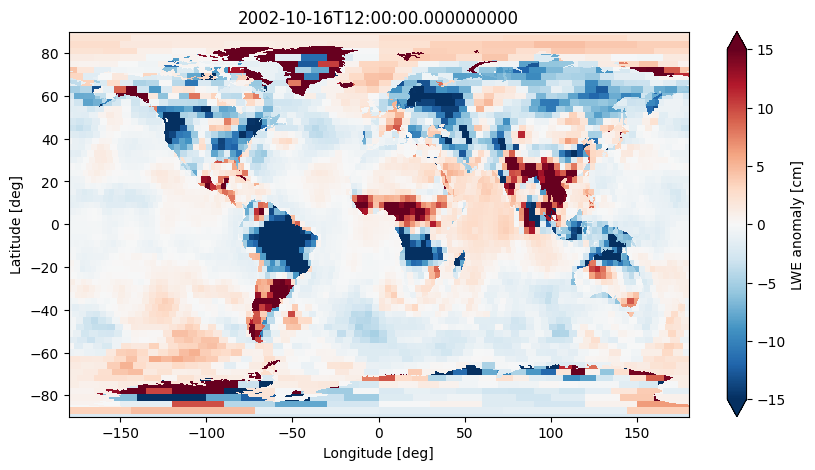

In [9]:
lwe = grace_data['lwe_thickness']

da = lwe.isel(time=4) # pick a month
plt.figure(figsize=(10,5))
da.plot(
    x='lon', y='lat',
    cmap='RdBu_r',
    vmin=-15, vmax=15,   
    cbar_kwargs={'label': 'LWE anomaly [cm]'}
)
plt.title(str(da.time.values))
plt.xlabel("Longitude [deg]")
plt.ylabel("Latitude [deg]")
plt.show()

In [10]:
# GRACE lwe_thickness is in cm water equivalent
lmask = grace_data["land_mask"]
scale = grace_data["scale_factor"]

# Apply mask + scaling and convert to mm
tws_mm = lwe * lmask * scale * 10.0  # convert cm → mm

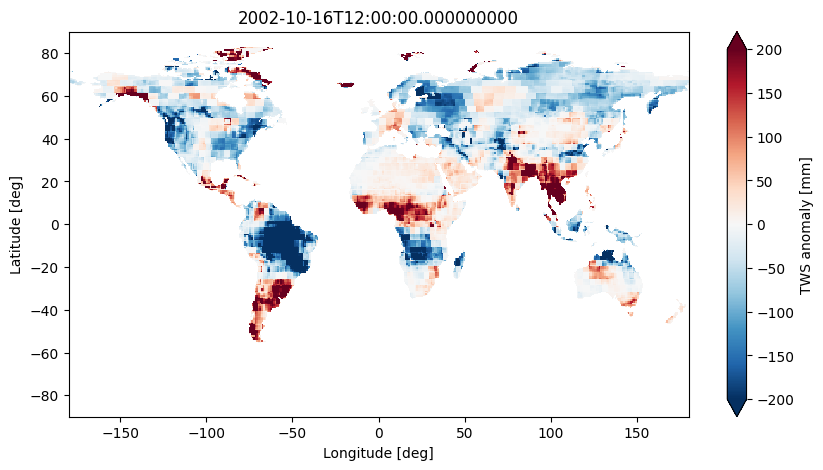

In [14]:
da = tws_mm.isel(time=4)
plt.figure(figsize=(10,5))
da.plot(
    x='lon', y='lat',
    cmap='RdBu_r',
    vmin=-200, vmax=200,  
    cbar_kwargs={'label': 'TWS anomaly [mm]'}
)
plt.title(str(da.time.values))
plt.xlabel("Longitude [deg]")
plt.ylabel("Latitude [deg]")
plt.show()

In [17]:
tws_mm.name = "twsa"

In [20]:
tws_mm.to_netcdf("/home/mgurazada/snowdroughts_thirst/data/grace_data/twsa.nc")